# All agents on the arm

This notebook compares the CBFE-ARX agent, with and without the information constraint, to the dual MPC, MPC with integrated experiment design (MPC-X), PILCO and TD-MPC2 baselines and to a fixed PD law. Every agent runs four rounds of the four reaching targets (48 s), with ten plant noise seeds, under three conditions: the payload stays at 0.5 kg; it rises to 1.5 kg after the first round; or the motor polarities are unknown, so that each motor may be reversed. The settings are the current defaults of `reaching.py`: goal variances halved and prior variance doubled relative to the first study, a torque limit of 4 N m, a planning horizon of 5 steps (0.5 s), and the backward-message planner of the CBFE-ARX agent.

All agents see the same information: the joint angles measured by encoders, the finite-difference joint velocities, the joint-space targets, and the action box that maps to the torque limit. Their prior knowledge comes from the same source, the nominal arm with the uncertain payload and damping at their prior means.

| agent | prior knowledge from the nominal arm | decision rule |
|---|---|---|
| CBFE-ARX, β = 0 | ARX posterior after 600 steps at weight 0.15 (90 effective observations) | constrained Bethe planner without the information constraint; backward messages through the linearised model, swept to a stationary point of the 5-step objective |
| CBFE-ARX, KKT β | same | with the information constraint, whose floor compares the spread that the uncertain coefficients cause in the predictions at the goal-reaching inputs with the goal prior; β is active while the model is too uncertain for the goal |
| dual MPC, λ = 0 | same model and prior | joint optimisation of the 5-step input sequence by IPOPT; λ = 0 was the best probing weight on held-out seeds |
| dual MPC, λ = 100 | same | probing weight of the earlier floor −H[p*], under which β saturated at 50 (λ = 2β) |
| MPC-X, γ = 0.0004 | same model and prior | nominal MPC (the dual-MPC cost without caution and probing) with the experiment-design constraint of Larsson et al. (ECC 2013): the information matrix at the end of the horizon must dominate the curvature of an application cost, scaled by a confidence quantile (α = 0.99) and the accuracy γ, and ramped up over 120 steps; γ = 4·10⁻⁴ was the best accuracy on held-out seeds |
| MPC-X, γ = 0.003 | same | accuracy at which the requirement switches off where the floor of the CBFE-ARX agent does |
| PILCO | 90 nominal transitions | GP-mean rollouts of 0.5 s, refits every second, PD anchor weight 3 (chosen on held-out seeds) |
| TD-MPC2 | pretrained on the nominal arm (several budgets) | world model, MPPI planning, keeps learning online; observes the joint error modulo 2π |
| PD | gains of the nominal excitation controller | fixed law, no learning |

Under unknown polarity, the ARX agents replace their prior over the coefficients that change sign with a motor by a zero-mean prior (`reaching.forget_polarity`), so that their prior is symmetric in both polarities. PILCO, TD-MPC2 and the PD law keep the nominal polarity, because their priors cannot express an unknown sign.

The episodes come from `experiment-arm/compare.py`, which needs torch for TD-MPC2 and therefore runs in the `torch` environment; this notebook loads its results from `results/compare/`. Sections 2–8 show TD-MPC2 with its largest pretraining budget, and Section 9 compares the budgets. Section 10 runs the fast agents live.

1. Results
2. The static task
3. Learning over four rounds
4. The payload rise
5. Unknown motor polarity
6. When the constraints are active
7. Example trajectories
8. Computation
9. TD-MPC2 and its pretraining budget
10. Playground
11. Takeaways

In [1]:
import os
for var in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(var, '1')

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'envs' / 'robot_arm.py').exists())
for path in (REPO_ROOT, REPO_ROOT / 'experiment-arm'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import reaching as R
import compare as C

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.width', 200)
s = R.Settings()

## 1. Results

The cell loads every saved episode and scores each round of four targets: the fraction of targets reached within 2 cm, the reach time, the holding error over the last second of each target, the RMS torque and the planning time per step.

In [2]:
records = C.load()
everything = C.per_round(records, s)
order = [a for a in C.agent_specs() if a in set(everything.agent)]
tdmpc2 = [a for a in order if a.startswith('TD-MPC2') and 'frozen' not in a]
frozen = [a for a in order if 'frozen' in a]
main = [a for a in order if not a.startswith('TD-MPC2')] + tdmpc2[-1:]   # largest TD-MPC2 budget
everything['agent'] = pd.Categorical(everything.agent, order, ordered=True)
rounds = everything[everything.agent.isin(main)].copy()
rounds['agent'] = pd.Categorical(rounds.agent.astype(str), main, ordered=True)
COLORS = {a: f'C{i}' for i, a in enumerate(main)}
print(f'{len(records)} episodes, agents: {order}')
print(f'Sections 2-8 show: {main}')
print(f'conditions: {sorted(set(rounds.condition))}, seeds per agent and condition: '
      f'{rounds.groupby(["agent", "condition"], observed=True).seed.nunique().min()}')

450 episodes, agents: ['CBFE-ARX, β = 0', 'CBFE-ARX, KKT β', 'dual MPC, λ = 0', 'dual MPC, λ = 100', 'MPC-X, γ = 0.0004', 'MPC-X, γ = 0.003', 'PILCO', 'PD', 'TD-MPC2, 5k steps', 'TD-MPC2, 10k steps', 'TD-MPC2, 20k steps', 'TD-MPC2, 30k steps', 'TD-MPC2, 40k steps', 'TD-MPC2, 50k steps', 'TD-MPC2, 50k steps, frozen']
Sections 2-8 show: ['CBFE-ARX, β = 0', 'CBFE-ARX, KKT β', 'dual MPC, λ = 0', 'dual MPC, λ = 100', 'MPC-X, γ = 0.0004', 'MPC-X, γ = 0.003', 'PILCO', 'PD', 'TD-MPC2, 50k steps']
conditions: ['no change', 'rise to 1.5 kg', 'unknown polarity'], seeds per agent and condition: 10


## 2. The static task

The first round of each episode, with the payload at 0.5 kg, is the static task of the earlier studies. The table and the figure pool the two conditions with the nominal polarity, which share their first round, and report means with standard errors over the twenty episodes.

In [3]:
first = rounds[(rounds['round'] == 1) & (rounds.condition != 'unknown polarity')]
metrics = ['reached', 'reach_time', 'hold_error', 'rms_torque', 'plan_time']
table = first.groupby('agent', observed=True)[metrics].agg(['mean', 'sem'])
table.round(3)

reached        reach_time        hold_error        rms_torque        plan_time       
                      mean    sem       mean    sem       mean    sem       mean    sem      mean    sem
agent                                                                                                   
CBFE-ARX, β = 0      1.000  0.000      1.283  0.045      3.358  0.055      3.225  0.016     0.040  0.002
CBFE-ARX, KKT β      1.000  0.000      1.323  0.045      3.228  0.058      3.228  0.015     0.094  0.005
dual MPC, λ = 0      1.000  0.000      1.405  0.057      3.297  0.040      3.250  0.012     0.018  0.001
dual MPC, λ = 100    1.000  0.000      1.425  0.056      3.378  0.043      3.307  0.009     0.041  0.003
MPC-X, γ = 0.0004    0.975  0.017      1.475  0.035      4.022  0.355      3.307  0.015     0.021  0.002
MPC-X, γ = 0.003     0.750  0.000      1.715  0.038     19.536  0.881      3.356  0.011     0.184  0.012
PILCO                1.000  0.000      1.483  0.032      1.782  0.144      1.430  0.021     0.297  0.020
PD                   1.000  0.000      1.630  0.015      1.925  0.052      1.868  0.011     0.000  0.000
TD-MPC2, 50k steps   0.750  0.000      1.905  0.002      3.896  0.134      1.349  0.006     0.604  0.038

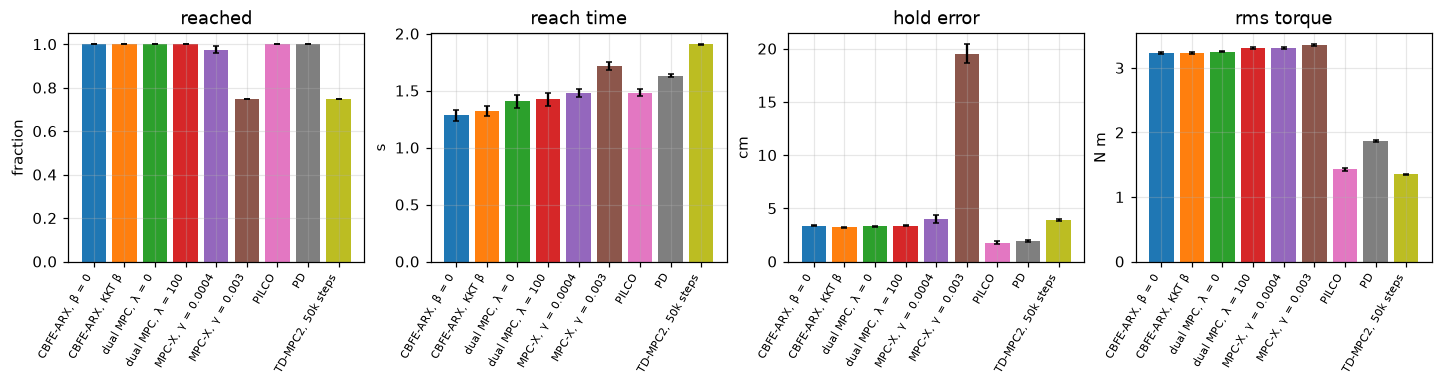

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4), layout='constrained')
g = first.groupby('agent', observed=True)
for ax, metric, unit in zip(axs, ('reached', 'reach_time', 'hold_error', 'rms_torque'),
                            ('fraction', 's', 'cm', 'N m')):
    m, se = g[metric].mean(), g[metric].sem()
    ax.bar(range(len(m)), m, yerr=se, color=[COLORS[a] for a in m.index], capsize=2)
    ax.set_xticks(range(len(m)), m.index, rotation=60, ha='right', fontsize=7)
    ax.set(title=metric.replace('_', ' '), ylabel=unit)
plt.show()

On the static task, the ARX planners, PILCO and the PD law reach 97.5–100 % of the targets in 1.3–1.6 s. They differ in precision and effort. PILCO and the PD law hold the targets within 1.8–1.9 cm with an RMS torque of 1.4–1.9 N m, while the ARX planners hold them within 3.2–4.0 cm and use 3.2–3.3 N m. The CBFE-ARX agents reach the targets fastest (1.28–1.32 s, against 1.41–1.43 s for the dual MPC and 1.48 s for the tuned MPC-X). The information constraint is active on 87 % of the steps of this round (Section 6); with it, the CBFE-ARX agent holds the targets at 3.2 cm, against 3.4 cm without it. The tuned MPC-X misses one target and holds the others at 4.0 cm. MPC-X with the requirement of the task floor reaches 75 % at 19.5 cm, because its experiment-design constraint takes over at the fourth target in every seed. TD-MPC2, after 50k pretraining steps, reaches 75 % of the targets in 1.9 s with the lowest torque (1.35 N m). It reaches targets 1, 3 and 4 in every episode and target 2 in none: there it stops 0.12 rad short at the shoulder and holds 10.5 cm away, against 1.7 cm at the other three targets.

## 3. Learning over four rounds

Without a payload change, the four rounds repeat the same targets, so the change from round to round shows what each agent learns online.

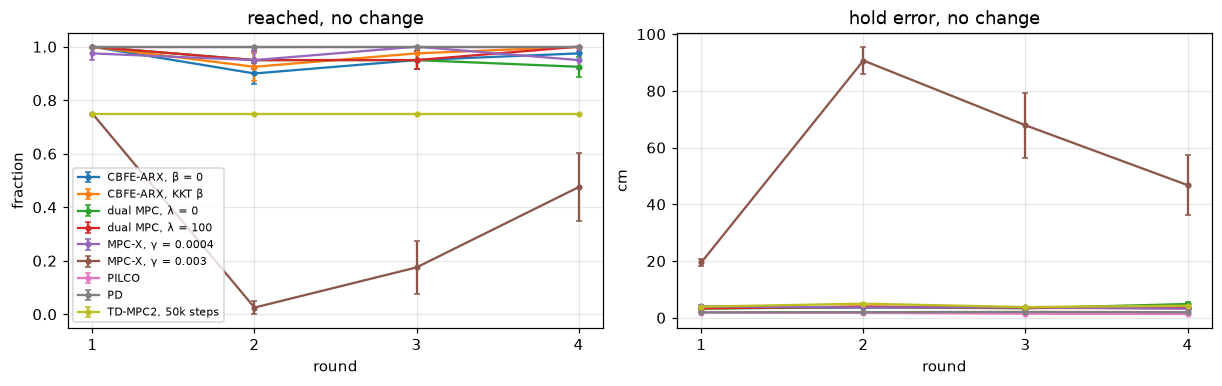

round,1,2,3,4
agent,,,,
"CBFE-ARX, β = 0",1.00,0.90,0.95,0.98
"CBFE-ARX, KKT β",1.00,0.92,0.98,1.00
"dual MPC, λ = 0",1.00,0.95,0.95,0.92
"dual MPC, λ = 100",1.00,0.95,0.95,1.00
"MPC-X, γ = 0.0004",0.98,0.95,1.00,0.95
"MPC-X, γ = 0.003",0.75,0.02,0.18,0.48
PILCO,1.00,1.00,1.00,1.00
PD,1.00,1.00,1.00,1.00
"TD-MPC2, 50k steps",0.75,0.75,0.75,0.75


In [5]:
def round_curves(cond, metrics=('reached', 'hold_error'), units=('fraction', 'cm')):
    data = rounds[rounds.condition == cond]
    fig, axs = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 3.4), layout='constrained')
    for agent in main:
        g = data[data.agent == agent].groupby('round')
        for ax, metric in zip(axs, metrics):
            ax.errorbar(g[metric].mean().index, g[metric].mean(), yerr=g[metric].sem(), marker='o', ms=3,
                        capsize=2, color=COLORS[agent], label=agent)
    for ax, metric, unit in zip(axs, metrics, units):
        ax.set(title=f'{metric.replace("_", " ")}, {cond}', xlabel='round', ylabel=unit, xticks=range(1, 5))
    axs[0].legend(fontsize='x-small', loc='lower left')
    return fig, axs

round_curves('no change')
plt.show()
rounds[rounds.condition == 'no change'].groupby(['agent', 'round'], observed=True)['reached'].mean() \
    .unstack('round').round(2)

Without a change, PILCO and the PD law reach every target in every round, and PILCO's holding error drops from 1.8 to 1.3 cm as its GP models collect data. The CBFE-ARX agents, the dual MPC and the tuned MPC-X reach 90–100 % of the targets per round at 3.2–4.8 cm, without a clear trend over the rounds. In rounds 2–4, the CBFE-ARX agent with the constraint, the dual MPC with λ = 100 and the tuned MPC-X miss four targets of 120 (97 %), and the CBFE-ARX agent without the constraint and the dual MPC with λ = 0 miss seven each (94 %). MPC-X with the requirement of the task floor reaches 3–48 % per round after the first, because its constraint keeps the torques near their limits (Section 6). TD-MPC2 reaches 75 % in every round and misses target 2 every time. Its online learning still matters: with frozen weights, the same checkpoint also misses target 1 in the later rounds, where it approaches from target 4 instead of the start configuration, and reaches 50–52 % in rounds 2–4 (Section 9).

## 4. The payload rise

After the first round, the payload rises from 0.5 to 1.5 kg (shaded rounds), which roughly halves the joint accelerations per unit torque. The figure shows the fraction of targets reached and the holding error per round; the table compares the mean over the rounds after the change with the same rounds without the change.

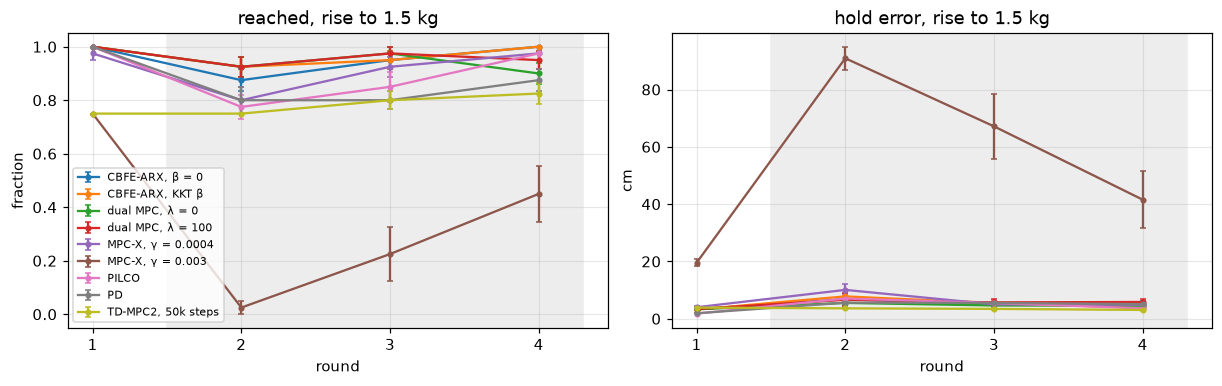

reached                hold_error               
condition          no change rise to 1.5 kg  no change rise to 1.5 kg
agent                                                                
CBFE-ARX, β = 0         0.94           0.94       3.51           5.65
CBFE-ARX, KKT β         0.97           0.96       3.61           5.69
dual MPC, λ = 0         0.94           0.93       3.96           4.91
dual MPC, λ = 100       0.97           0.95       3.66           6.07
MPC-X, γ = 0.0004       0.97           0.90       3.50           6.66
MPC-X, γ = 0.003        0.22           0.23      68.45          66.53
PILCO                   1.00           0.87       1.48           5.40
PD                      1.00           0.82       2.00           5.43
TD-MPC2, 50k steps      0.75           0.79       4.32           3.39

In [6]:
cond_rise = f'rise to {C.NEW_PAYLOAD} kg'
fig, axs = round_curves(cond_rise)
for ax in axs:
    ax.axvspan(1.5, 4.3, color='0.93', zorder=0)
plt.show()
after = rounds[(rounds['round'] > 1) & (rounds.condition != 'unknown polarity')].groupby(['agent', 'condition'], observed=True)[['reached', 'hold_error']].mean()
after.unstack('condition').round(2)

The payload rise separates the ARX planners from the other agents. The CBFE-ARX agents, the dual MPC and the tuned MPC-X keep 90–96 % of the targets in the rounds after the change at 4.9–6.7 cm, nearly as many as without the change (94–97 %). PILCO drops to 78 % in the first heavy round and recovers to 98 % by the last. The PD law, which learns nothing, keeps 80–88 % at about 5.4 cm. TD-MPC2 keeps 75–83 % and holds the targets more precisely than without the change (3.4 against 4.3 cm); in rounds 3 and 4 it even reaches target 2 in 20–30 % of the episodes. The CBFE-ARX agent and the dual MPC share the ARX model, the feature map and the prior, and with its backward messages the CBFE planner minimises the same 5-step objective as the dual MPC, up to the shape of the control prior. After the change, these five ARX agents differ by at most seven of the 120 targets: the tuned MPC-X misses 12, the others 5–8. With the earlier one-step planner (`planner="sweeps"`, episodes in `results/compare/sweeps_planner/`), the CBFE-ARX agents fell to 69–72 % after the change, with holding errors of 21–24 cm.

## 5. Unknown motor polarity

Under unknown polarity, each motor of the arm may be reversed. The seeds cycle through the four polarity pairs: (+, +) in seeds 0, 4 and 8, (+, −) in 1, 5 and 9, (−, +) in 2 and 6, and (−, −) in 3 and 7. The polarity does not change during an episode, so the four rounds show how fast each agent finds the control direction and what it does afterwards. The table lists the fraction of targets reached per round, and the second table splits it by polarity pair for the agents that keep the nominal polarity.

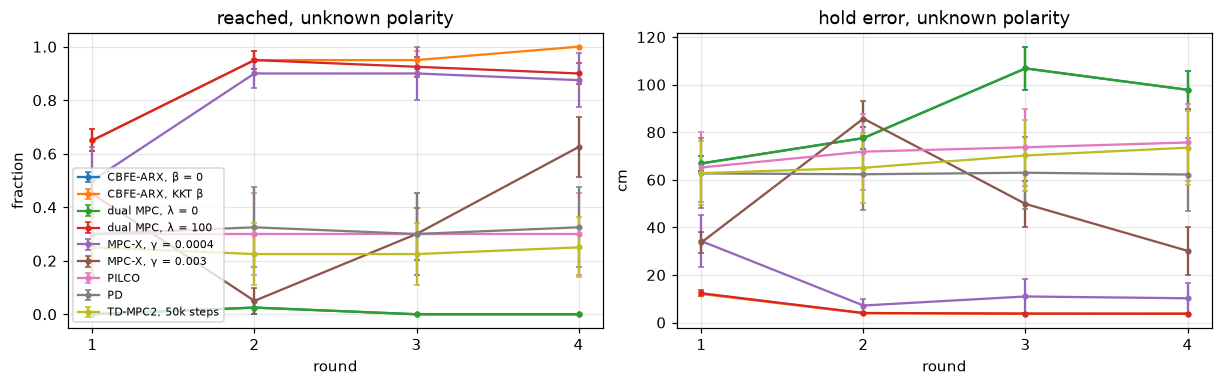

round,1,2,3,4,missed of 160
agent,,,,,
"CBFE-ARX, β = 0",0.00,0.02,0.00,0.00,159
"CBFE-ARX, KKT β",0.65,0.95,0.95,1.00,18
"dual MPC, λ = 0",0.00,0.02,0.00,0.00,159
"dual MPC, λ = 100",0.65,0.95,0.92,0.90,23
"MPC-X, γ = 0.0004",0.50,0.90,0.90,0.88,33
"MPC-X, γ = 0.003",0.45,0.05,0.30,0.62,103
PILCO,0.30,0.30,0.30,0.30,112
PD,0.30,0.32,0.30,0.32,110
"TD-MPC2, 50k steps",0.25,0.22,0.22,0.25,122


In [7]:
cond_polarity = 'unknown polarity'
round_curves(cond_polarity)
plt.show()
pol = rounds[rounds.condition == cond_polarity]
table = pol.groupby(['agent', 'round'], observed=True)['reached'].mean().unstack('round').round(2)
table['missed of 160'] = pol.groupby('agent', observed=True).reached.apply(lambda x: round(float(4 * (1 - x).sum())))
table

In [8]:
pairs = pol.assign(pair=pol.seed.map(lambda k: str(R.POLARITIES[k % 4])))
pairs[pairs.agent.isin(['PILCO', 'PD', tdmpc2[-1]])].groupby(['agent', 'pair'], observed=True)['reached'].mean() \
    .unstack('pair').round(2)

pair,"(-1.0, -1.0)","(-1.0, 1.0)","(1.0, -1.0)","(1.0, 1.0)"
agent,,,,
PILCO,0.0,0.00,0.00,1.00
PD,0.0,0.00,0.04,1.00
"TD-MPC2, 50k steps",0.0,0.06,0.00,0.75


Information gathering decides this condition. Without probing, the ARX agents never move: the CBFE-ARX agent without the constraint and the dual MPC with λ = 0 reach 1 of 160 targets, because under the symmetric prior every input only adds predicted spread. The CBFE-ARX agent with the constraint and the dual MPC with λ = 100 probe in round 1 and reach 65 % of the targets of that round, and 90–100 % per round from round 2 on, once they know the polarities. Afterwards the constraint switches off (active on 34 %, 6 % and 4 % of the steps of rounds 2–4, Section 6), and the CBFE-ARX agent misses 4 of the 120 targets of rounds 2–4, against 9 for the dual MPC with its fixed probing weight. Overall it misses 18 of 160 targets, the fewest of all agents. The tuned MPC-X reaches 50 % in round 1 and holds the later targets at 7–11 cm (33 misses), and MPC-X with the requirement of the task floor misses 103.

PILCO, TD-MPC2 and the PD law assume the nominal polarity. They reach 100 % (PILCO, PD) and 75 % (TD-MPC2) when both motors keep it, and almost nothing when a motor is reversed, so they reach 30 %, 24 % and 31 % overall. Online learning does not rescue PILCO or TD-MPC2 within four rounds: their models start from data in which every torque acts the nominal way, and the reversed motor drives the arm away from the targets that the models expect it to reach.

## 6. When the constraints are active

The CBFE-ARX agent with the constraint and MPC-X excite the arm only while their information requirement binds. The table lists the fraction of steps on which it binds, per round and condition: β > 0 for the CBFE-ARX agent, and an experiment-design constraint that shapes the input for MPC-X. The figure follows the episode with noise seed 0 and the payload rise. It shows the floor $\beta_t$ of the CBFE-ARX agent against the information $(n_y/2)\ln(1 + \ell)$ of its inputs, its multiplier, and the steps on which the constraint of each MPC-X variant binds. Thin lines mark the target switches, and the shading marks the heavy payload.

In [9]:
constrained = [a for a in main if a == 'CBFE-ARX, KKT β' or a.startswith('MPC-X')]
rounds[rounds.agent.isin(constrained)].groupby(['agent', 'condition', 'round'], observed=True)['active'] \
    .mean().unstack('round').round(2)

round                                  1     2     3     4
agent             condition                               
CBFE-ARX, KKT β   no change         0.87  0.21  0.04  0.03
                  rise to 1.5 kg    0.87  0.20  0.04  0.01
                  unknown polarity  1.00  0.34  0.06  0.04
MPC-X, γ = 0.0004 no change         0.00  0.00  0.00  0.00
                  rise to 1.5 kg    0.00  0.00  0.00  0.00
                  unknown polarity  0.03  0.00  0.00  0.00
MPC-X, γ = 0.003  no change         0.26  0.99  0.77  0.41
                  rise to 1.5 kg    0.26  0.94  0.51  0.13
                  unknown polarity  0.53  0.98  0.57  0.20

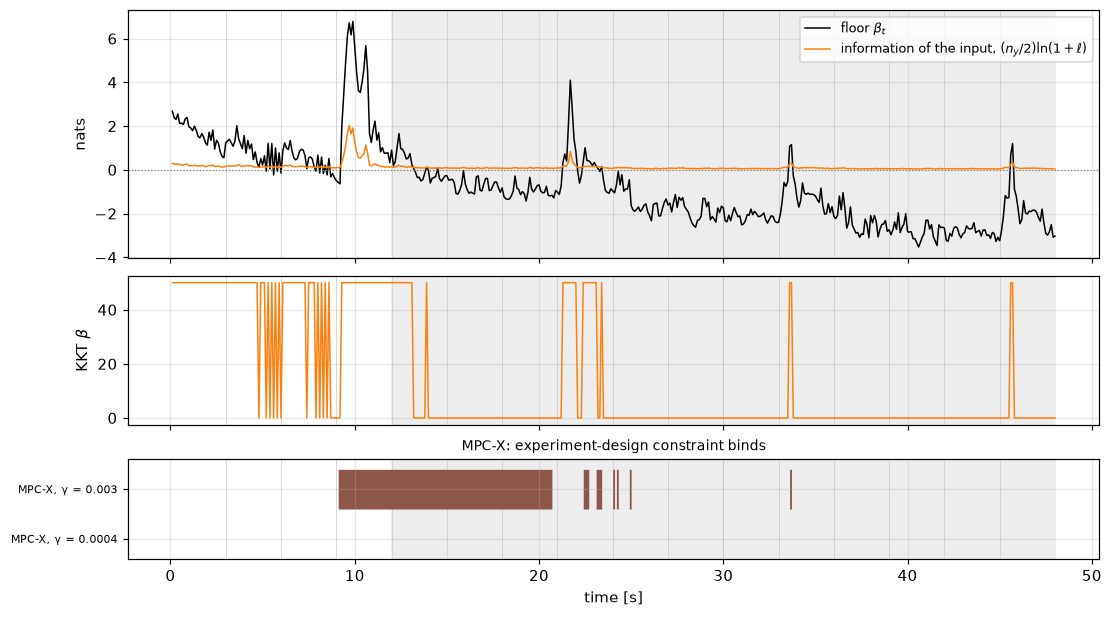

In [10]:
examples = {rec['agent']: rec['episode'] for rec in records
            if rec['condition'] == cond_rise and rec['seed'] == 0}
kkt = examples['CBFE-ARX, KKT β']
t = np.arange(1, len(kkt.actions) + 1) * kkt.dt
n_y = kkt.ys.shape[1]
mpcx = [a for a in constrained if a.startswith('MPC-X')]
fig, axs = plt.subplots(3, 1, figsize=(10, 5.5), sharex=True, layout='constrained',
                        gridspec_kw={'height_ratios': [2, 1.2, 0.8]})
axs[0].plot(t, kkt.floor, color='k', lw=1, label=r'floor $\beta_t$')
axs[0].plot(t, n_y / 2 * np.log1p(kkt.leverage), color=COLORS['CBFE-ARX, KKT β'], lw=1,
            label=r'information of the input, $(n_y/2)\ln(1+\ell)$')
axs[0].axhline(0, color='0.5', lw=0.8, ls=':')
axs[0].set(ylabel='nats')
axs[0].legend(fontsize='small', loc='upper right')
axs[1].plot(t, kkt.beta, color=COLORS['CBFE-ARX, KKT β'], lw=1)
axs[1].set(ylabel=r'KKT $\beta$')
for i, agent in enumerate(mpcx):
    axs[2].fill_between(t, i, i + 0.8 * (examples[agent].beta > 0), step='pre', color=COLORS[agent], lw=0)
axs[2].set(yticks=np.arange(len(mpcx)) + 0.4, ylim=(0, len(mpcx)))
axs[2].set_yticklabels(mpcx, fontsize=7)
axs[2].set_title('MPC-X: experiment-design constraint binds', fontsize=9)
for ax in axs:
    ax.axvspan(12, t[-1], color='0.93', zorder=0)
    for k in range(1, len(t) // s.steps_per_target):
        ax.axvline(k * s.seconds_per_target, color='0.8', lw=0.5, zorder=0)
axs[-1].set_xlabel('time [s]')
plt.show()

The floor of the CBFE-ARX agent follows the reaching cycle. In round 1, a new target calls for torques that the nominal prior covers poorly: the floor exceeds what any input delivers, β saturates at 50 at the start of 96 % of the moves, and it stays positive through most of the holding phase. From round 2 on, the floor turns negative while the arm holds (β = 0 on 94–100 % of the last half-second of each target), and the saturation at the start of a move fades, from about 40 % of the moves in round 2 to 0–3 % in round 4. Over the rounds, the constraint is active on 87 % of the steps of round 1 (mean β = 44), 20–21 % of round 2, 4 % of round 3 and 1–3 % of round 4 (mean β ≈ 1). The payload rise does not reactivate it, because the stationary ARX model keeps accumulating precision $\Lambda_t$ after the change, and only the larger noise estimate $R_t$ could raise the floor. Under unknown polarity, the constraint is active on every step of round 1 and on 34 %, 6 % and 4 % of the steps of rounds 2–4.

The tuned MPC-X binds on 0.3 % of the steps of round 1 with the nominal polarity, and on 3 % under unknown polarity, so it acts as the nominal MPC. With the requirement of the task floor, MPC-X starts to bind when its ramp approaches the full requirement at the fourth target, and it binds on 94–99 % of the steps of round 2. A 5-step horizon cannot deliver that much information: in seed 0 of the payload rise, no plan meets the requirement on 94 % of the binding steps, so the agent maximises the attainable information instead, and on 72–79 % of the binding steps at least one torque is within 5 % of its limit. The CBFE-ARX agent faces a requirement that switches off at the same model accuracy, but its multiplier weighs the information against the goal, so an unattainable floor saturates β at 50 instead of overriding the tracking cost.

## 7. Example trajectories

Joint angles of every agent in the episode with noise seed 0 and the payload rise, against the joint-space goals (dashed). The shading marks the heavy payload. The arm has no joint limits, and TD-MPC2 turns the shoulder through a whole turn in every round, so the figure shows the shoulder angle modulo 2π, in [−π, π). A curve that leaves the panel at one edge re-enters at the other.

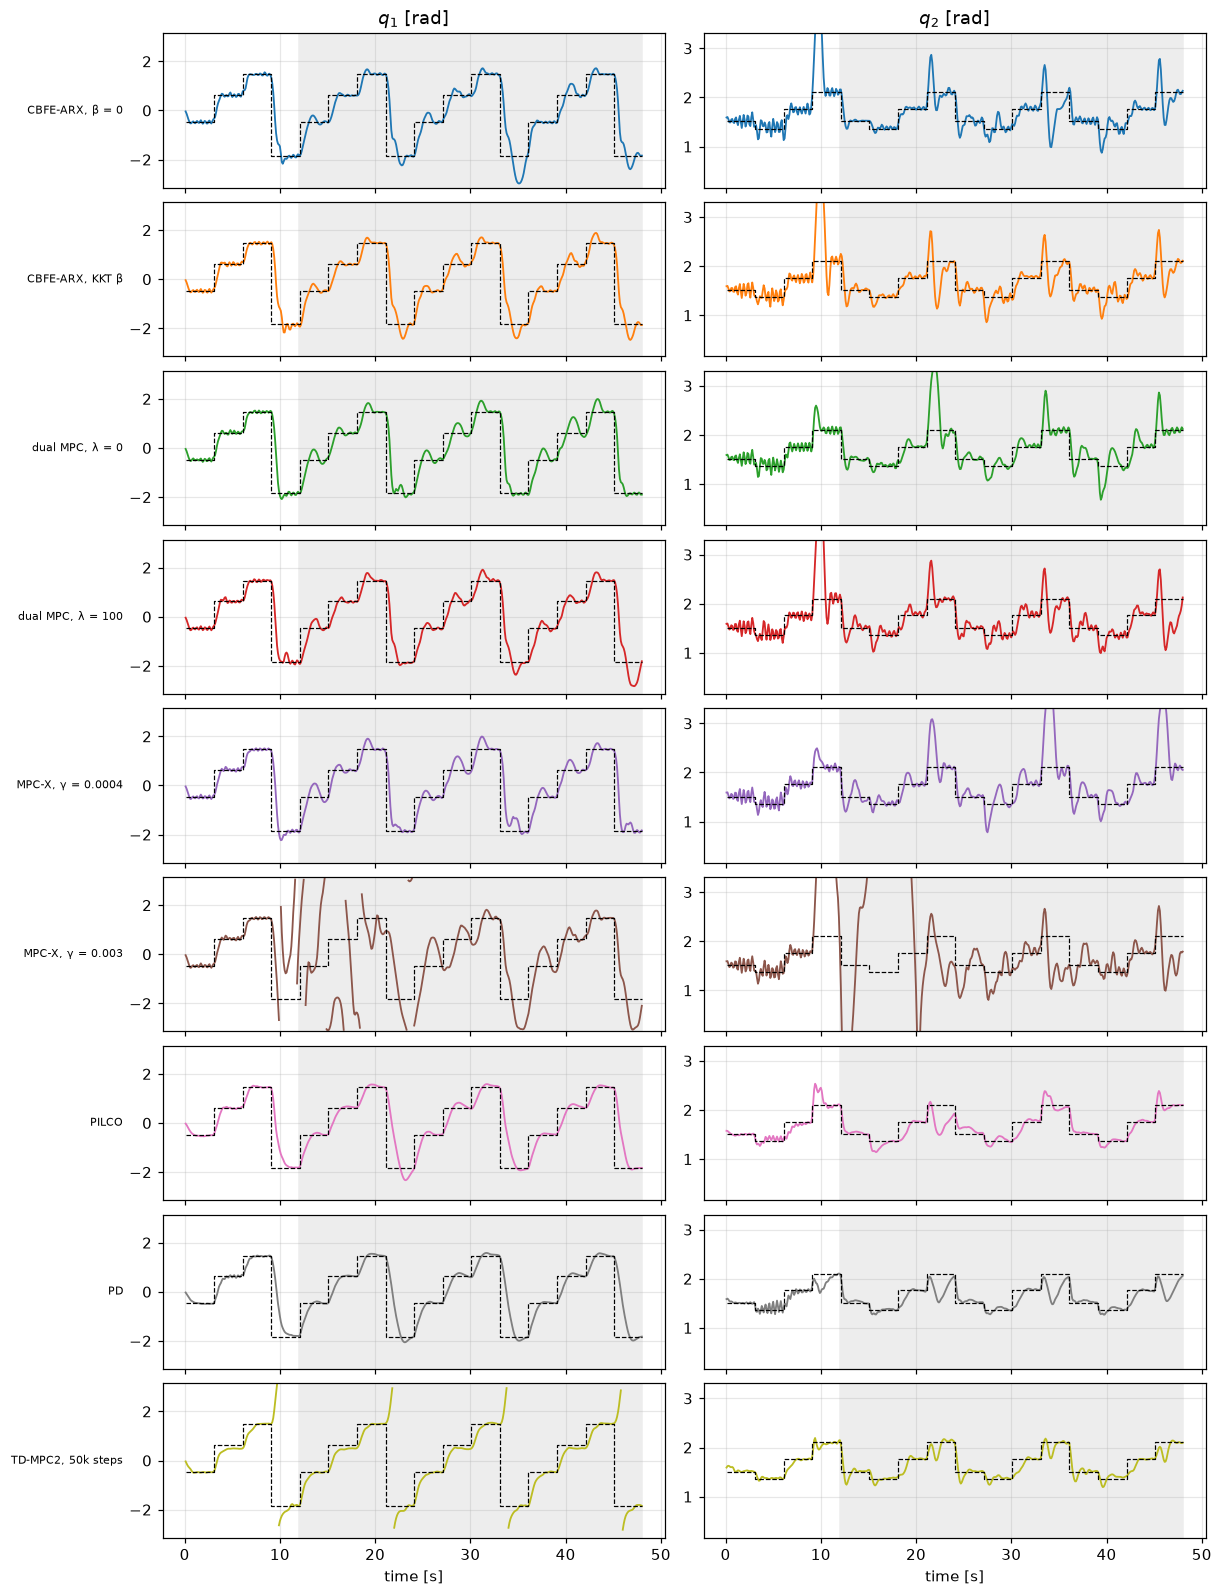

In [11]:
def modulo_2pi(q):
    # angle in [-π, π), with a gap at every wrap so that the line breaks there
    w = (q + np.pi) % (2 * np.pi) - np.pi
    w[1:][np.abs(np.diff(w)) > np.pi] = np.nan
    return w

fig, axs = plt.subplots(len(main), 2, figsize=(11, 1.6 * len(main)), sharex=True, layout='constrained')
for row, agent in enumerate(main):
    ep = examples[agent]
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    q_goal = R.joint_targets(ep.targets)
    for j in range(2):
        ax = axs[row, j]
        ax.plot(t, modulo_2pi(ep.xs[1:, 0]) if j == 0 else ep.xs[1:, 1], color=COLORS[agent], lw=1.2)
        ax.step(t, q_goal[:, j], 'k--', lw=0.8, where='post')
        ax.axvspan(12, t[-1], color='0.93', zorder=0)
        ax.set_ylim((-np.pi, np.pi) if j == 0 else (q_goal[:, 1].min() - 1.2, q_goal[:, 1].max() + 1.2))
    axs[row, 0].set_ylabel(agent, fontsize=7, rotation=0, ha='right', va='center')
axs[0, 0].set_title('$q_1$ [rad]')
axs[0, 1].set_title('$q_2$ [rad]')
axs[-1, 0].set_xlabel('time [s]')
axs[-1, 1].set_xlabel('time [s]')
plt.show()

In the heavy rounds, the ARX planners overshoot every move by about 0.3 rad at the shoulder (medians over seeds and heavy rounds). They swing the elbow to 2.8–2.9 rad against a goal of 2.1 rad, but settle before the next target. MPC-X with the requirement of the task floor overshoots the moves to targets 1 and 4 by 0.7 and 1.4 rad, because its constraint keeps exciting the arm. PILCO and the PD law overshoot by less than 0.2 rad with about half the torque of the ARX planners. TD-MPC2 hardly overshoots (0.04 rad), approaches the targets more slowly, and stops short of target 2 in every round. It also reaches target 4 the other way round, because its observation contains the joint error modulo 2π and that way is 2.97 rad instead of 3.31 rad. The other agents receive the joint goals without wrapping and take the direct way, so one move in four is 10 % shorter for TD-MPC2.

## 8. Computation

Mean planning time per control step over the episodes with the nominal polarity, i.e., the time from the output to the action. TD-MPC2's time includes the MPPI planner but not its online network update, which runs in the learning step. All agents ran on one CPU thread each.

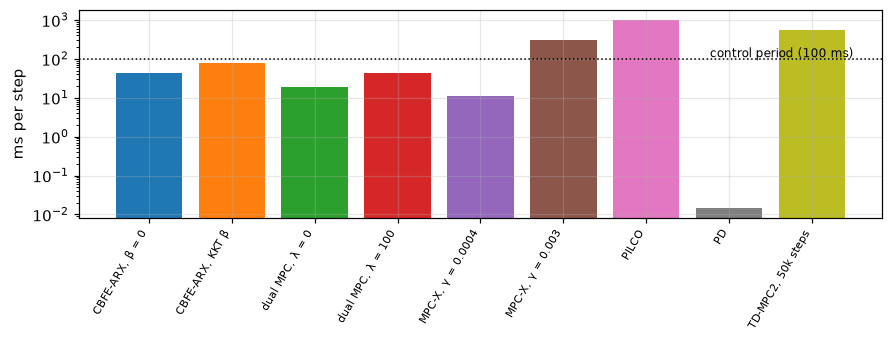

agent
CBFE-ARX, β = 0         43.7
CBFE-ARX, KKT β         76.9
dual MPC, λ = 0         18.5
dual MPC, λ = 100       42.9
MPC-X, γ = 0.0004       11.4
MPC-X, γ = 0.003       314.2
PILCO                 1022.5
PD                       0.0
TD-MPC2, 50k steps     556.2
Name: ms per step, dtype: float64

In [12]:
plan = rounds[rounds.condition != 'unknown polarity'].groupby('agent', observed=True)['plan_time'].mean()
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.bar(range(len(plan)), 1000 * plan, color=[COLORS[a] for a in plan.index])
ax.axhline(100, color='k', ls=':', lw=1)
ax.text(len(plan) - 0.5, 110, 'control period (100 ms)', ha='right', fontsize=8)
ax.set_xticks(range(len(plan)), plan.index, rotation=60, ha='right', fontsize=7)
ax.set(yscale='log', ylabel='ms per step')
plt.show()
(1000 * plan).round(1).rename('ms per step')

The ARX planners need 11–77 ms per step on one thread, within the 100 ms control period. The CBFE-ARX agent with the constraint needs about 30 ms more than without it, because it solves the one-step program at β = 0 to test the constraint even when the constraint turns out inactive, and sweeps a second time from a symmetric start while β > 0. MPC-X with the requirement of the task floor needs 0.3 s per step, because its two-phase program with a 19 × 19 matrix inequality runs whenever the constraint binds. PILCO needs about 1 s per step on average, because every refit fits four GPs and solves a rollout NLP, and the refits slow down as the data grow. TD-MPC2 needs 0.56 s per step for its MPPI planner alone (0.41–0.65 s across the checkpoints and conditions). On this machine, PILCO, TD-MPC2 and the strict MPC-X could not run at 10 Hz in real time.

## 9. TD-MPC2 and its pretraining budget

TD-MPC2 learns its world model, value and policy from reward alone, so it pretrains on the nominal arm with random targets (`train_tdmpc2.py`). The left panel shows its training curve; the right panel the fraction of evaluation targets it reaches in the first round, per checkpoint. The first table adds the rounds after the payload rise. The second table compares, for the largest checkpoint, the agent that keeps learning online with the same agent with frozen weights, per round of the condition without a change.

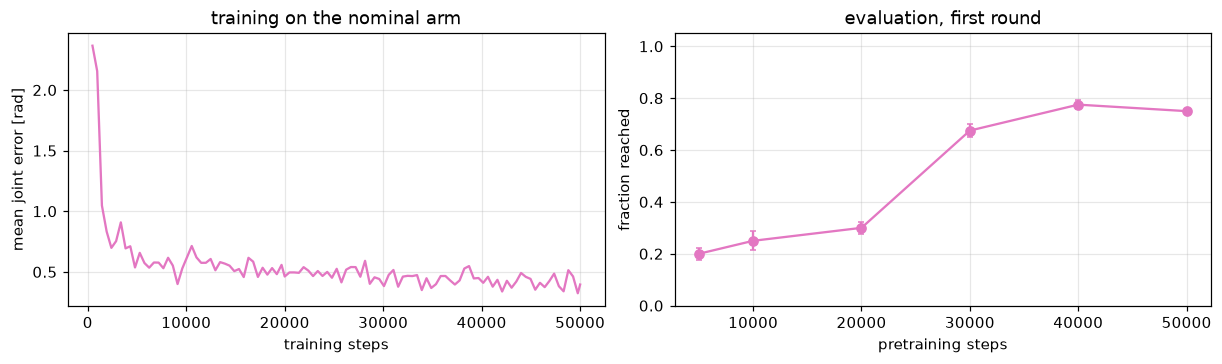

first round                       after the rise           
          reached reach_time hold_error        reached hold_error
steps                                                            
5000         0.20       2.74      21.27           0.17      24.75
10000        0.25       2.83      15.28           0.03      28.87
20000        0.30       2.69      11.20           0.28      14.99
30000        0.68       2.70       6.70           0.43       9.04
40000        0.78       1.82       3.95           0.58       6.31
50000        0.75       1.90       3.90           0.79       3.39

In [13]:
log = np.loadtxt(C.CHECKPOINTS / 'train_log.csv', delimiter=',', skiprows=1)
budget = everything[(everything['round'] == 1) & everything.agent.isin(tdmpc2)
                    & (everything.condition != 'unknown polarity')].copy()
budget['steps'] = budget.agent.astype(str).str.extract(r'(\d+)k').astype(int)[0] * 1000
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout='constrained')
axs[0].plot(log[:, 0], log[:, 2], color='C6')
axs[0].set(xlabel='training steps', ylabel='mean joint error [rad]', title='training on the nominal arm')
g = budget.groupby('steps')
axs[1].errorbar(g.reached.mean().index, g.reached.mean(), yerr=g.reached.sem(), marker='o', color='C6', capsize=2)
axs[1].set(xlabel='pretraining steps', ylabel='fraction reached', title='evaluation, first round', ylim=(0, 1.05))
plt.show()
heavy = everything[(everything['round'] > 1) & (everything.condition == f'rise to {C.NEW_PAYLOAD} kg')
                   & everything.agent.isin(tdmpc2)].copy()
heavy['steps'] = heavy.agent.astype(str).str.extract(r'(\d+)k').astype(int)[0] * 1000
pd.concat({'first round': g[['reached', 'reach_time', 'hold_error']].mean(),
           'after the rise': heavy.groupby('steps')[['reached', 'hold_error']].mean()}, axis=1).round(2)

In [14]:
pair = tdmpc2[-1:] + frozen
online_vs_frozen = everything[everything.agent.isin(pair) & (everything.condition == 'no change')]
online_vs_frozen.groupby(['agent', 'round'], observed=True)[['reached', 'hold_error']].mean().unstack('round').round(2)

reached                   hold_error                  
round                            1     2     3     4          1     2     3     4
agent                                                                            
TD-MPC2, 50k steps            0.75  0.75  0.75  0.75       3.90  4.96  3.76  4.25
TD-MPC2, 50k steps, frozen    0.75  0.50  0.50  0.52       3.53  5.35  5.59  5.39

TD-MPC2's training error falls from 1.1 rad over the first 5k steps to 0.41 rad over the last 5k, a figure that includes the approach after every target switch and the exploration noise. On the evaluation targets, the fraction reached in the first round stays at 20–30 % up to 20k steps, rises to 68 % after 30k and to 75–78 % after 40k and 50k steps, while the holding error falls from 21 to 3.9 cm. The rounds after the payload rise follow the same trend, from 3–28 % up to 20k steps to 79 % after 50k. Online learning matters at the largest budget: without a change, the online agent reaches 75 % in every round, whereas the frozen agent drops to 50–52 % in rounds 2–4 because it also misses target 1. 50k steps are 83 min of simulated experience and took 3.2 h of training on four CPU threads, whereas the ARX agents start from 600 simulated steps (1 min).

## 10. Playground

Run one episode of a fast agent (CBFE-ARX, dual MPC, MPC-X or PD) with the chosen settings and press **Run Interact**. The figure shows the end-effector distance to the targets and the joint angles. PILCO and TD-MPC2 take minutes per episode and run through `compare.py`.

In [15]:
from dataclasses import replace
from ipywidgets import interact_manual, widgets

@interact_manual(agent=widgets.Dropdown(options=['CBFE-ARX, β = 0', 'CBFE-ARX, KKT β', 'dual MPC', 'MPC-X', 'PD'],
                                        value='dual MPC'),
                 lambda_dual=widgets.FloatLogSlider(value=1, base=10, min=-1, max=2.5, step=0.1),
                 gamma=widgets.FloatLogSlider(value=4e-4, base=10, min=-5, max=-2, step=0.1),
                 new_payload=widgets.FloatSlider(value=C.NEW_PAYLOAD, min=0.0, max=3.0, step=0.25),
                 rounds_=widgets.IntSlider(value=2, min=1, max=4, description='rounds'),
                 horizon=widgets.IntSlider(value=s.horizon, min=1, max=15),
                 u_max=widgets.FloatSlider(value=s.u_max, min=1.0, max=6.0, step=0.5),
                 seed=widgets.IntSlider(value=0, min=0, max=20),
                 unknown_polarity=widgets.Checkbox(value=False, description='unknown polarity'))
def playground(agent, lambda_dual, gamma, new_payload, rounds_, horizon, u_max, seed, unknown_polarity):
    sp = replace(s, horizon=horizon, u_max=u_max, polarity_known=not unknown_polarity)
    spec = {'CBFE-ARX, β = 0': {'kind': 'cbfe', 'fixed_beta': 0.0},
            'CBFE-ARX, KKT β': {'kind': 'cbfe', 'fixed_beta': None},
            'dual MPC': {'kind': 'dual', 'lambda_dual': lambda_dual},
            'MPC-X': {'kind': 'mpcx', 'gamma': gamma},
            'PD': {'kind': 'pd'}}[agent]
    tg, ch = R.payload_change(new_payload, sp, rounds=rounds_)
    ep = R.run_agent(spec, seed, sp, targets=tg, changes=ch if rounds_ > 1 else None)
    for r in range(rounds_):
        sc = R.summarise(ep, sp, slice(4 * r, 4 * r + 4))
        print(f'round {r + 1}: reached {sc["reached"]:.2f}, reach {sc["reach_time"]:.2f} s, '
              f'hold {sc["hold_error"]:.1f} cm, RMS torque {sc["rms_torque"]:.2f} N m')
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout='constrained')
    axs[0].plot(t, 100 * ep.distance, color='C3')
    axs[0].axhline(100 * R.REACH_TOL, color='k', lw=0.8, ls=':')
    axs[0].set(yscale='log', ylabel='distance [cm]')
    qg = R.joint_targets(ep.targets)
    for j in range(2):
        axs[1 + j].plot(t, ep.xs[1:, j], color='C3')
        axs[1 + j].step(t, qg[:, j], 'k--', lw=1, where='post')
        axs[1 + j].set(ylabel=f'$q_{j + 1}$ [rad]')
    if rounds_ > 1:
        for ax in axs:
            ax.axvspan(next(iter(ch)) * sp.dt, t[-1], color='0.92', zorder=0)
    axs[-1].set_xlabel('time [s]')
    plt.show()

interactive(children=(Dropdown(description='agent', index=2, options=('CBFE-ARX, β = 0', 'CBFE-ARX, KKT β', 'd…

## 11. Takeaways


- **With backward messages, the CBFE-ARX agent plans as well as the dual MPC.** After the rise to 1.5 kg, the CBFE-ARX agents, the dual MPC and the tuned MPC-X keep 90–96 % of the targets, and on the static task the CBFE-ARX agents reach the targets fastest (1.28–1.32 s). Both planners minimise the same 5-step objective on the same ARX model and prior, up to the shape of the control prior. With the earlier one-step planner, the CBFE-ARX agents fell to 69–72 % after the rise.
- **A fixed PD law is a strong reference.** It matches the best learning agents on the static task (100 %, 1.9 cm) and keeps 80–88 % of the targets after the rise.
- **PILCO holds the targets most precisely without a change (1.3–1.8 cm) and recovers almost fully from the rise** (98 % in the last round), but it needs about 1 s of computation per 0.1 s control step.
- **TD-MPC2 trails on the static task even after 50k pretraining steps.** It reaches 75 % of the targets, against 100 % for the other agents, because it misses target 2 in every round. After the rise, it keeps 79 %, less than the PD law (82 %) and the ARX planners (90–96 %). It depends on online learning (frozen, it reaches 51 % in the later rounds without a change) and needs 0.56 s per step for planning, after 3.2 h of pretraining.
- **Under unknown motor polarity, information gathering decides the outcome.** Without probing, the ARX agents never move (1 of 160 targets). PILCO, TD-MPC2 and the PD law assume the nominal polarity and reach 24–31 %. The CBFE-ARX agent with the constraint probes in round 1, switches the constraint off as it learns, and misses 18 of 160 targets, the fewest of all agents (dual MPC with λ = 100: 23, tuned MPC-X: 33).
- **With the task floor, the information constraint switches itself off as the model learns.** It is active on 87 % of the steps of the first round, where the new targets call for torques that the nominal prior covers poorly, and on 1–3 % of the last round. With the nominal polarity it does not change the ranking: in rounds 2–4, the CBFE-ARX agent misses 4 of 120 targets without a change and 5 after the rise, against 7 and 7 without the constraint. The earlier floor −H[p*] saturated β at 50 on every step (episodes in `results/compare/negentropy_floor/`).
- **MPC-X stays useful only with a lax accuracy.** At its best accuracy on held-out seeds, the experiment-design constraint binds on at most 3 % of the steps, so MPC-X acts as the nominal MPC (97 % without a change, 90 % after the rise, 79 % under unknown polarity). With the requirement of the task floor as a hard constraint, the horizon cannot deliver the information, the constraint drives the torques to their limits, and the arm reaches 23–36 % of the targets. The CBFE-ARX agent faces a requirement that switches off at the same model accuracy, but its multiplier only weighs information against the goal.